In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
import numpy as np
import optuna
import ast


df = pd.read_csv("../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv")

In [15]:
#Variable independiente es immunogenicity y me quedo solo con las variables numericas

X = df.select_dtypes(include=['float64', 'int64']).drop(columns=['immunogenicity'])
y = df['immunogenicity']

In [16]:
# Dividir el conjunto de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 100, 2000)
    max_depth = trial.suggest_int('max_depth', 10, 70)  # más profundidad
    min_samples_split = trial.suggest_int('min_samples_split', 2, 15)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 5)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.1, 0.3, 0.5, 0.7])
    sampling_strategy = trial.suggest_categorical('sampling_strategy', ['auto', 'not minority', 'all', 'majority', 1, 0.75, 0.5])
    bootstrap = trial.suggest_categorical('bootstrap', [True, False])
    max_samples = trial.suggest_float('max_samples', 0.5, 1.0)
    replacement = trial.suggest_categorical('replacement', [True, False])
    criterion = trial.suggest_categorical('criterion', ['gini', 'entropy', 'log_loss'])
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])

    brf = BalancedRandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        sampling_strategy=sampling_strategy,
        bootstrap=bootstrap,
        max_samples=max_samples,
        replacement=replacement,
        criterion=criterion,
        class_weight=class_weight,
        random_state=42,
        n_jobs=32
    )

    scores = cross_val_score(brf, X_train, y_train, cv=5, scoring='roc_auc', n_jobs=1)
    return np.mean(scores)

In [18]:
import os


def load_best_trial_from_csv(filename='../results/reports/Optuna_Results/optuna_results_general.csv', metric='roc_auc', model_name=None):
    if not os.path.exists(filename):
        return None

    try:
        df_results = pd.read_csv(filename)

        # Aplicar filtros
        if model_name is not None:
            df_results = df_results[df_results['model'] == model_name]

        filtered = df_results[df_results['metric'] == metric]

        if filtered.empty:
            return None

        # Obtener mejor resultado
        best_entry = filtered.sort_values(by='result', ascending=False).iloc[0]
        best_params = ast.literal_eval(best_entry['best_params'])

        return optuna.trial.FixedTrial(best_params)

    except Exception:
        # Cualquier error (archivo corrupto, formato incorrecto, etc.)
        return None

In [19]:
import src.utils.Optuna_Utils as ou

best_trial = load_best_trial_from_csv(model_name='BalancedRandomForestClassifier')

study = optuna.create_study(direction='maximize')

if best_trial is not None:
    study.enqueue_trial(best_trial.params)

study.optimize(objective, n_trials=100)  # ejecuta 200 pruebas o más

print('Mejores parámetros:', study.best_params)
print('Mejor AUC:', study.best_value)


ou.save_optuna_result(
    model_name='BalancedRandomForestClassifier',
    metric='roc_auc',
    value=study.best_value,
    best_params=study.best_params,
    filepath="../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv"
)


[I 2026-01-26 12:25:53,604] A new study created in memory with name: no-name-ed0ba5a3-9677-47d0-8167-1339aae14122
[I 2026-01-26 12:26:43,542] Trial 0 finished with value: 0.7958547480052328 and parameters: {'n_estimators': 1603, 'max_depth': 57, 'min_samples_split': 12, 'min_samples_leaf': 1, 'max_features': 0.1, 'sampling_strategy': 'all', 'bootstrap': False, 'max_samples': 0.5469898297620808, 'replacement': False, 'criterion': 'log_loss', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.7958547480052328.
[I 2026-01-26 12:27:25,769] Trial 1 finished with value: 0.8076831031644585 and parameters: {'n_estimators': 539, 'max_depth': 41, 'min_samples_split': 13, 'min_samples_leaf': 1, 'max_features': 0.7, 'sampling_strategy': 0.5, 'bootstrap': True, 'max_samples': 0.8817303040888671, 'replacement': True, 'criterion': 'log_loss', 'class_weight': 'balanced'}. Best is trial 1 with value: 0.8076831031644585.
[I 2026-01-26 12:28:10,197] Trial 2 finished with value: 0.792301

Mejores parámetros: {'n_estimators': 277, 'max_depth': 29, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 0.7, 'sampling_strategy': 1, 'bootstrap': False, 'max_samples': 0.6091896684118742, 'replacement': True, 'criterion': 'entropy', 'class_weight': None}
Mejor AUC: 0.8146372878015843


OSError: Cannot save file into a non-existent directory: 'results/reports/Optuna_Results'

In [8]:
# Filtrar solo los resultados de BalancedRandomForestClassifier

df = pd.read_csv('../results/reports/Optuna_Results/optuna_results_general.csv')

brf_results = df[df['model'] == 'BalancedRandomForestClassifier'].copy()

# Ordenar por resultado (métrica) descendente y tomar el mejor
brf_results = brf_results.sort_values('result', ascending=False)
best_brf_result = brf_results.iloc[0]

print(f"Mejor resultado de BalancedRandomForestClassifier: {best_brf_result['result']}")
print(f"Parámetros: {best_brf_result['best_params']}")

# Convertir la cadena de parámetros a diccionario
best_params = ast.literal_eval(best_brf_result['best_params'])

# Verificar y adaptar parámetros según sea necesario
# Algunos parámetros podrían necesitar ajustes
adapted_params = best_params.copy()

# Asegurarse de que max_features sea float si es un número decimal
if 'max_features' in adapted_params and isinstance(adapted_params['max_features'], str):
    try:
        adapted_params['max_features'] = float(adapted_params['max_features'])
    except:
        # Si no se puede convertir a float, mantener el valor original
        pass

# Asegurarse de que max_samples sea float si es un número decimal
if 'max_samples' in adapted_params and isinstance(adapted_params['max_samples'], str):
    try:
        adapted_params['max_samples'] = float(adapted_params['max_samples'])
    except:
        pass

# Crear y entrenar el modelo con los mejores parámetros
brf = BalancedRandomForestClassifier(
    n_estimators=adapted_params['n_estimators'],
    max_depth=adapted_params['max_depth'],
    min_samples_split=adapted_params['min_samples_split'],
    min_samples_leaf=adapted_params['min_samples_leaf'],
    max_features=adapted_params['max_features'],
    sampling_strategy=adapted_params['sampling_strategy'],
    bootstrap=adapted_params['bootstrap'],
    max_samples=adapted_params.get('max_samples', None),  # Usar get por si no existe
    replacement=adapted_params['replacement'],
    criterion=adapted_params['criterion'],
    random_state=42,
    n_jobs=32,
    verbose=1  # Para ver el progreso del entrenamiento
)

# Si existe class_weight en los parámetros, agregarlo
if 'class_weight' in adapted_params:
    brf.set_params(class_weight=adapted_params['class_weight'])

print("Entrenando BalancedRandomForestClassifier con los mejores parámetros...")
brf.fit(X_train, y_train)

print("¡Modelo entrenado exitosamente!")

Mejor resultado de BalancedRandomForestClassifier: 0.761180479262494
Parámetros: {'n_estimators': 1867, 'max_depth': 70, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 0.7, 'sampling_strategy': 'majority', 'bootstrap': True, 'max_samples': 0.7817341926647929, 'replacement': True, 'criterion': 'entropy', 'class_weight': 'balanced'}
Entrenando BalancedRandomForestClassifier con los mejores parámetros...


[Parallel(n_jobs=32)]: Using backend ThreadingBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done 136 tasks      | elapsed:    1.4s
[Parallel(n_jobs=32)]: Done 386 tasks      | elapsed:    3.5s
[Parallel(n_jobs=32)]: Done 736 tasks      | elapsed:    6.5s
[Parallel(n_jobs=32)]: Done 1186 tasks      | elapsed:   10.2s
[Parallel(n_jobs=32)]: Done 1736 tasks      | elapsed:   15.1s
[Parallel(n_jobs=32)]: Done 1867 out of 1867 | elapsed:   16.1s finished


¡Modelo entrenado exitosamente!


In [9]:
# Hacer predicciones en el conjunto de prueba
y_pred = brf.predict(X_test)

[Parallel(n_jobs=32)]: Using backend ThreadingBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done 136 tasks      | elapsed:    0.0s
[Parallel(n_jobs=32)]: Done 386 tasks      | elapsed:    0.1s
[Parallel(n_jobs=32)]: Done 736 tasks      | elapsed:    0.1s
[Parallel(n_jobs=32)]: Done 1186 tasks      | elapsed:    0.2s
[Parallel(n_jobs=32)]: Done 1736 tasks      | elapsed:    0.3s
[Parallel(n_jobs=32)]: Done 1867 out of 1867 | elapsed:    0.3s finished


In [10]:
# Evaluar el modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.58


In [11]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred, labels=brf.classes_)
print(cm)

[[823 818]
 [ 47 372]]


In [12]:
# Reporte de clasificación
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.95      0.50      0.66      1641
           1       0.31      0.89      0.46       419

    accuracy                           0.58      2060
   macro avg       0.63      0.69      0.56      2060
weighted avg       0.82      0.58      0.62      2060



Importancia de las características:
1. Feature mutant_rank_netMHCpan (0.11029729525398227)
2. Feature DAI_NetMHC (0.0781906059753374)
3. Feature DAI_NetStab (0.07623677096833177)
4. Feature mut_Rank_Stab (0.07563114223934966)
5. Feature DAI_MixMHC (0.06916498694235869)
6. Feature TAP_score (0.06611094293134952)
7. Feature mut_binding_score (0.06344469059335499)
8. Feature mut_netchop_score_ct (0.060566982027504934)
9. Feature foreignness_score (0.05774191666415379)
10. Feature mutant_rank_PRIME (0.051552014606493356)
11. Feature mutant_rank (0.050626760776312195)
12. Feature Sample_Tissue_expression_GTEx (0.046135601378230286)
13. Feature GTEx_all_tissues_expression_mean (0.04413357227200765)
14. Feature TCGA_Cancer_expression (0.04275730058017479)
15. Feature hydrophobicity_avg_diff (0.03670528677177251)
16. Feature pep_mut_start (0.02667259870577012)
17. Feature hydrophobicity_total_diff (0.026074271581042297)
18. Feature seq_len (0.017024171544709945)
19. Feature DAI_MixMHC_mbp (0.0

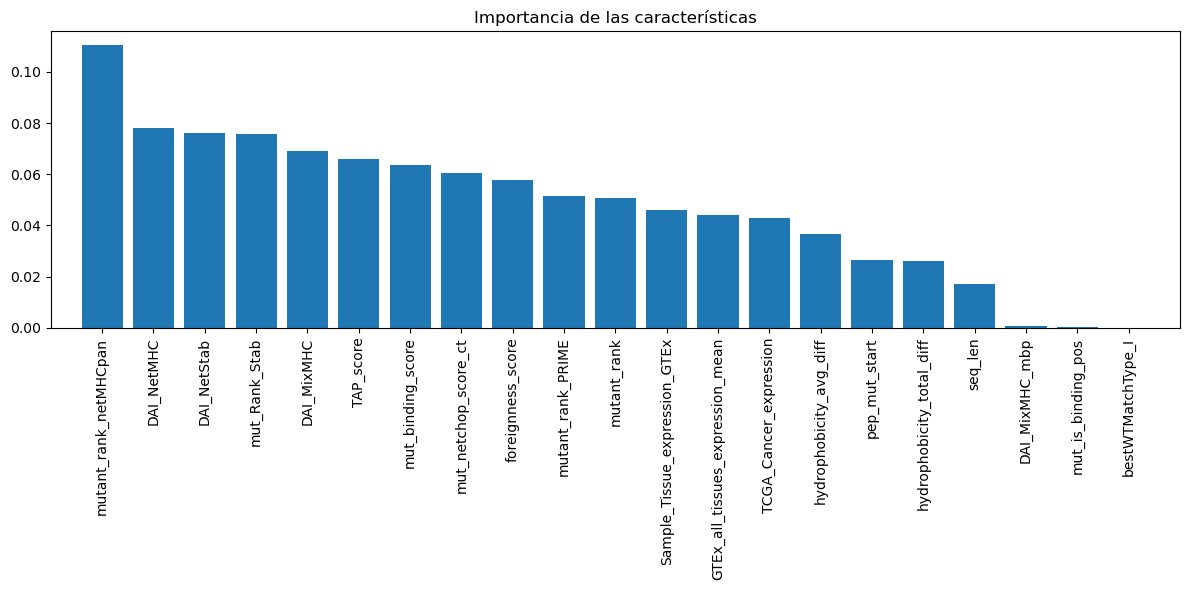

In [13]:
# Veo la importancia de las características
import matplotlib.pyplot as plt
importances = brf.feature_importances_
indices = np.argsort(importances)[::-1]
# Imprimir la importancia de las características
print("Importancia de las características:")
for f in range(X.shape[1]):
    print(f"{f + 1}. Feature {X.columns[indices[f]]} ({importances[indices[f]]})")
# Graficar la importancia de las características
plt.figure(figsize=(12, 6))
plt.title("Importancia de las características")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), X.columns[indices], rotation=90)
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, auc

# ==========================================================
#  Funciones métricas estilo NeoRanking
# ==========================================================

def fraction_ranked(y_true, y_scores):
    """
    Fraction Ranked (FR): proporción de inmunogénicos (y_true==1)
    que tienen un score válido (no NaN).
    """
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)
    positives = y_true == 1
    if positives.sum() == 0:
        return np.nan
    ranked = ~np.isnan(y_scores[positives])
    return ranked.sum() / positives.sum()

def top_n_recall(y_true, y_scores, n=20):
    """
    Porcentaje de inmunogénicos (positivos) que están en el top-N
    según el score del modelo.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_score': y_scores})
    df = df.sort_values('y_score', ascending=False).reset_index(drop=True)
    top_n = df.head(n)
    if df['y_true'].sum() == 0:
        return np.nan
    return top_n['y_true'].sum() / df['y_true'].sum()

def ttif(y_true, y_scores, n=20):
    """
    Top-N Immunogenic Fraction (TTIF): fracción del top-N
    que realmente es inmunogénico.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_score': y_scores})
    df = df.sort_values('y_score', ascending=False).reset_index(drop=True)
    top_n = df.head(n)
    return top_n['y_true'].sum() / len(top_n)

# ==========================================================
# 📊 Calcular métricas
# ==========================================================

# Fraction Ranked
fr_value = fraction_ranked(y_test, y_pred_proba)

# TTIF y Top-N Recall
ttif_20 = ttif(y_test, y_pred_proba, n=20)
recall_20 = top_n_recall(y_test, y_pred_proba, n=20)
recall_50 = top_n_recall(y_test, y_pred_proba, n=50)
recall_100 = top_n_recall(y_test, y_pred_proba, n=100)

# AUPRC (por si quieres tenerlo junto)
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
auprc = auc(recall, precision)

# ==========================================================
# Mostrar resultados
# ==========================================================
print("===== Métricas estilo NeoRanking =====")
print(f"Fraction Ranked (FR): {fr_value:.3f}")
print(f"Top-20 Immunogenic Fraction (TTIF): {ttif_20:.3f}")
print(f"Top-20 Recall: {recall_20:.3f}")
print(f"Top-50 Recall: {recall_50:.3f}")
print(f"Top-100 Recall: {recall_100:.3f}")
print(f"AUPRC: {auprc:.3f}")
